# Día 4 — Clustering: segmentar clientes de tarjeta de crédito

**Módulo 3: Machine Learning Aplicado — CEC EPN / Banco Central del Ecuador**

Hasta ahora siempre conocíamos la respuesta `y`. Hoy **no hay respuesta**: tenemos 8 950 clientes de tarjeta de crédito y queremos descubrir **grupos de clientes que se comportan parecido**.

## Cómo está organizado

| Paso | Qué hacemos |
|---|---|
| 1. Mirar los datos | Cargar, `head`, tipos y resumen |
| 2. Entender y graficar | Qué es una fila, cómo se distribuyen las variables |
| 3. Limpiar y preparar | Faltantes, logaritmo y escalado, **paso a paso con el antes y el después** |
| 4. Dividir | Train y Validation, para comprobar que los grupos se sostienen con clientes nuevos |
| 5. K-Means a mano | Con 12 clientes y una sola variable |
| 6. K-Means simple con scikit-learn | Pocas líneas, comentadas |
| 7. Métricas a mano y con scikit-learn | Inercia y Silhouette, en Train y en Validation |
| 8. Los hiperparámetros, uno por uno | Qué hace cada uno |
| 9. Probar combinaciones con `for` | Varios `k` y preparaciones, contra una línea base |
| 10. Modelo final | Perfiles de los grupos y qué hacer con ellos |
| 11. Clustering jerárquico | El mismo recorrido: a mano, simple, hiperparámetros, `for` |
| 12. Comparación final | Todos los métodos en todos los datasets del día |

## El dataset

**Credit Card Dataset for Clustering** (Kaggle, autor Arjun Bhasin). Cada fila es un cliente activo de tarjeta de crédito con su comportamiento de los últimos 6 meses. No trae ninguna etiqueta de grupo. Los montos están en dólares; no describe a clientes del Ecuador.

## Antes de empezar: aprendizaje supervisado y no supervisado

El Machine Learning tiene dos grandes familias.

**Aprendizaje supervisado** (Días 1 a 3). Es como estudiar con un profesor que entrega los ejercicios ya resueltos: cada fila de entrenamiento trae las características `X` **y la respuesta** `y`. El modelo aprende la relación entre ambas y luego predice `y` para filas nuevas. Como la respuesta existe, podemos medir exactamente cuánto se equivoca: MAE si `y` es un número (regresión), F1 si `y` es una clase (clasificación).

**Aprendizaje no supervisado** (desde hoy). Es como recibir una caja con miles de fotos sin etiquetas y ordenarlas por parecido: las filas solo traen características, **no hay `y`**. El algoritmo busca estructura por sí solo y nosotros interpretamos lo que encontró. Tareas típicas: **clustering** (agrupar filas parecidas, hoy), **reducción de dimensiones** (resumir muchas variables en pocas, PCA, Día 5) y **detección de casos raros**. Como no hay respuesta correcta, se evalúa la coherencia, la estabilidad y la utilidad de lo encontrado.

| | Supervisado | No supervisado |
|---|---|---|
| ¿Los datos traen `y`? | Sí | **No** |
| ¿Qué aprende? | A predecir `y` a partir de `X` | Estructura: grupos o patrones |
| Tareas | Regresión, clasificación | Clustering, reducción de dimensiones, casos raros |
| Algoritmos del módulo | Lineal, árboles, bosque, KNN, SVM | K-Means, jerárquico, PCA |
| Cómo se evalúa | Error frente a la respuesta real (MAE, F1) | Silhouette, estabilidad e interpretación |
| Riesgo típico | Memorizar Train (sobreajuste) | Grupos sin significado: el algoritmo siempre entrega grupos |
| Ejemplo bancario | ¿Este cliente abandonará la tarjeta? | ¿Qué tipos de clientes tenemos? |

**La pregunta clave:** ¿mis datos históricos traen la respuesta que quiero obtener? Si sí, es supervisado; si no, no supervisado.

**Practica.** ¿Supervisado o no supervisado?

1. Estimar el monto de crédito que pedirá un cliente, con historial de montos → supervisado (regresión).
2. Detectar fraude con transacciones ya marcadas como fraude o normal → supervisado (clasificación).
3. Agrupar provincias según sus indicadores económicos → no supervisado (clustering).
4. Encontrar transacciones raras cuando nadie sabe cuáles son fraude → no supervisado (casos raros).

*Cuidado:* KNN (Día 3, supervisado) y K-Means (hoy, no supervisado) se parecen en el nombre y en que usan distancias, pero resuelven problemas distintos.

## ¿Qué es clustering?

En **clasificación** el dataset ya trae la clase de cada fila (fraude o normal) y el modelo aprende a reproducirla. En **clustering** no hay clase: el algoritmo agrupa filas que se parecen según las variables que **nosotros** elegimos. Por eso se llama aprendizaje **no supervisado**: nadie le dice al algoritmo cuál es la respuesta correcta.

| | Regresión | Clasificación | Clustering |
|---|---|---|---|
| ¿Hay variable objetivo `y`? | Sí, un número | Sí, una clase | **No** |
| Pregunta | ¿Cuánto? | ¿Cuál clase? | ¿Qué grupos de filas parecidas hay? |
| Cómo se evalúa | MAE, RMSE, R² | Matriz de confusión, F1 | Silhouette, tamaños e **interpretación** |
| Ejemplo bancario | Monto que transará un cliente | ¿Abandonará la tarjeta? | Perfiles de uso de la tarjeta |

**Vocabulario.** *Cluster*: un grupo propuesto por el algoritmo. *Centroide*: el punto promedio de un grupo. *Distancia*: qué tan diferentes son dos filas. *Inercia*: suma de las distancias al cuadrado de cada fila a su centroide. *Silhouette*: qué tan bien separado está cada punto de los otros grupos.

**Dos familias de clustering.** **K-Means** agrupa alrededor de centros: decidimos antes cuántos grupos queremos (`k`) y cada fila va al centro más cercano; es rápido incluso con millones de filas. El **clustering jerárquico** construye un árbol de uniones: cada fila empieza sola y se van juntando las más parecidas; el número de grupos se elige al final, cortando el árbol. Los dos usan distancias, así que los dos necesitan datos limpios y escalados.

**Advertencia central.** Un algoritmo de clustering **siempre** entrega grupos, aunque los datos no tengan grupos reales. El valor está en que los grupos se puedan **describir, explicar y usar**; no en un número alto.

# 0. Librerías

En algunos equipos con Windows y Anaconda, K-Means muestra avisos de memoria o de núcleos del procesador. Fijamos un hilo **antes** de importar scikit-learn para evitarlos; no cambia los resultados.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

from pathlib import Path
import numpy as np                      # cálculos numéricos
import pandas as pd                     # tablas
import matplotlib.pyplot as plt         # gráficos
from sklearn.model_selection import train_test_split               # dividir en Train y Validation
from sklearn.preprocessing import StandardScaler                   # estandarizar
from sklearn.cluster import KMeans, AgglomerativeClustering        # K-Means y jerárquico
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram            # dibujar el dendrograma

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
DATA_DIR = Path("datos") if Path("datos").is_dir() else Path("../datos")
ARCHIVO = DATA_DIR / "CC_GENERAL.csv"
print("Archivo:", ARCHIVO.resolve())

Archivo: C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\CC_GENERAL.csv


# 1. Mirar los datos

In [2]:
cc = pd.read_csv(ARCHIVO)
print("Filas y columnas:", cc.shape)
cc.head()

Filas y columnas: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


| Columna | Qué es |
|---|---|
| `CUST_ID` | Identificador del cliente (no se usa para agrupar) |
| `BALANCE` | Saldo adeudado en la tarjeta |
| `BALANCE_FREQUENCY` | Qué tan seguido se actualiza el saldo (0 a 1) |
| `PURCHASES` | Total de compras en 6 meses |
| `ONEOFF_PURCHASES` / `INSTALLMENTS_PURCHASES` | Compras de un solo pago / en cuotas |
| `CASH_ADVANCE` | Avances en efectivo (retirar dinero con la tarjeta) |
| `PURCHASES_FREQUENCY` | Qué tan seguido compra (0 = nunca, 1 = todos los meses) |
| `ONEOFF_` / `PURCHASES_INSTALLMENTS_FREQUENCY` | Frecuencia de compras de un pago / en cuotas |
| `CASH_ADVANCE_FREQUENCY`, `CASH_ADVANCE_TRX` | Frecuencia y número de avances |
| `PURCHASES_TRX` | Número de compras |
| `CREDIT_LIMIT` | Límite de crédito |
| `PAYMENTS` | Total pagado |
| `MINIMUM_PAYMENTS` | Pagos mínimos realizados |
| `PRC_FULL_PAYMENT` | Proporción de meses en que pagó el saldo total (0 a 1) |
| `TENURE` | Meses de antigüedad del servicio |

In [3]:
cc.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

In [4]:
cc[["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]].describe().round(1)

,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT
count,8950.0,8950.0,8950.0,8949.0,8950.0,8950.0
mean,1564.5,1003.2,978.9,4494.4,1733.1,0.2
std,2081.5,2136.6,2097.2,3638.8,2895.1,0.3
min,0.0,0.0,0.0,50.0,0.0,0.0
25%,128.3,39.6,0.0,1600.0,383.3,0.0
50%,873.4,361.3,0.0,3000.0,856.9,0.0
75%,2054.1,1110.1,1113.8,6500.0,1901.1,0.1
max,19043.1,49039.6,47137.2,30000.0,50721.5,1.0


**Lee las salidas.** 8 950 clientes, cada uno una sola vez. Faltan valores en `MINIMUM_PAYMENTS` y `CREDIT_LIMIT` (su `Non-Null Count` es menor). En `PURCHASES` el promedio (≈ 1 003) es casi el triple de la mediana (≈ 361) y el máximo llega a ≈ 49 000: unos pocos clientes gastan muchísimo. En `CASH_ADVANCE` la mediana es 0: más de la mitad **nunca** hizo un avance.

# 2. Entender y graficar

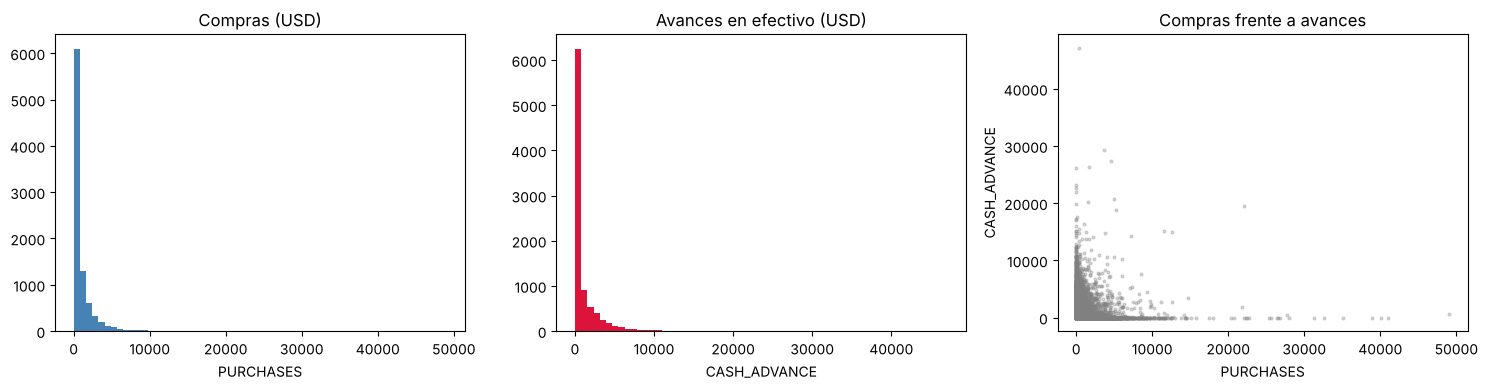

Clientes sin ninguna compra: 22.8%
Clientes sin avances en efectivo: 51.7%


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(cc["PURCHASES"], bins=60, color="steelblue"); ax[0].set(title="Compras (USD)", xlabel="PURCHASES")
ax[1].hist(cc["CASH_ADVANCE"], bins=60, color="crimson"); ax[1].set(title="Avances en efectivo (USD)", xlabel="CASH_ADVANCE")
ax[2].scatter(cc["PURCHASES"], cc["CASH_ADVANCE"], s=4, alpha=0.3, color="gray")
ax[2].set(title="Compras frente a avances", xlabel="PURCHASES", ylabel="CASH_ADVANCE")
plt.tight_layout(); plt.show()
print("Clientes sin ninguna compra:", f"{(cc['PURCHASES'] == 0).mean():.1%}")
print("Clientes sin avances en efectivo:", f"{(cc['CASH_ADVANCE'] == 0).mean():.1%}")

**Interpretación.** Las dos distribuciones están amontonadas cerca de 0 con colas larguísimas: variables **muy asimétricas**. En el gráfico de la derecha casi todo el mundo queda en una esquina. Así, unos pocos clientes enormes dominarían cualquier distancia. Además, hay dos comportamientos: clientes que compran y clientes que usan avances.

# 3. Limpiar y preparar, paso a paso

**Paso 1: faltantes.** K-Means no puede medir distancias con datos faltantes.

In [6]:
print("Faltantes por columna:"); print(cc.isna().sum()[cc.isna().sum() > 0])
cc = cc.dropna(subset=["CREDIT_LIMIT"]).copy()                     # 1 cliente sin límite: lo quitamos
mediana_min = cc["MINIMUM_PAYMENTS"].median()
cc["MINIMUM_PAYMENTS"] = cc["MINIMUM_PAYMENTS"].fillna(mediana_min)  # 313 faltantes: los rellenamos con la mediana
print("Mediana usada para MINIMUM_PAYMENTS:", round(mediana_min, 1), "| Clientes que quedan:", len(cc))

Faltantes por columna:
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64
Mediana usada para MINIMUM_PAYMENTS: 312.5 | Clientes que quedan: 8949


Eliminar los 313 clientes sería perder el 3,5 %; preferimos rellenar con la mediana y **declararlo**.

**Paso 2: escoger variables.** `CUST_ID` es un nombre, no un comportamiento. De las 17 restantes elegimos 9 que describen **cómo** se usa la tarjeta, evitando las que repiten casi lo mismo (por ejemplo, `PURCHASES_TRX` y `PURCHASES_FREQUENCY`).

In [7]:
VARS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
        "PURCHASES_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]
MONTOS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]
cc[VARS].head()

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT
0,40.900749,95.40,0.00,95.4,0.000000,0.166667,1000.0,201.802084,0.000000
1,3202.467416,0.00,0.00,0.0,6442.945483,0.000000,7000.0,4103.032597,0.222222
2,2495.148862,773.17,773.17,0.0,0.000000,1.000000,7500.0,622.066742,0.000000
3,1666.670542,1499.00,1499.00,0.0,205.788017,0.083333,7500.0,0.000000,0.000000
4,817.714335,16.00,16.00,0.0,0.000000,0.083333,1200.0,678.334763,0.000000


**Paso 3: el logaritmo para los montos.** La transformación $\log(1+x)$ comprime los valores grandes y conserva el orden; usamos $1+x$ porque $\log(0)$ no existe. Así, pasar de 100 a 1 000 USD pesa parecido a pasar de 1 000 a 10 000: importa la **proporción**. No la aplicamos a las variables que ya están entre 0 y 1 (frecuencia y porcentaje de pago total). A mano, para el primer cliente:

In [8]:
fila0 = cc[VARS].iloc[0]
for v in ["BALANCE", "PURCHASES", "CREDIT_LIMIT"]:
    print(f"{v:14s} {fila0[v]:9.2f} → log(1 + {fila0[v]:.2f}) = {np.log1p(fila0[v]):.3f}")
con_log = cc[VARS].copy()
con_log[MONTOS] = np.log1p(con_log[MONTOS])         # aplicar log(1 + x) solo a los montos
print("\nAntes del logaritmo:"); print(cc[VARS].head(3).round(2))
print("\nDespués del logaritmo:"); print(con_log.head(3).round(2))

BALANCE            40.90 → log(1 + 40.90) = 3.735
PURCHASES          95.40 → log(1 + 95.40) = 4.569
CREDIT_LIMIT     1000.00 → log(1 + 1000.00) = 6.909

Antes del logaritmo:
   BALANCE  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  CREDIT_LIMIT  PAYMENTS  PRC_FULL_PAYMENT
0    40.90      95.40              0.00                    95.4          0.00                 0.17        1000.0    201.80              0.00
1  3202.47       0.00              0.00                     0.0       6442.95                 0.00        7000.0   4103.03              0.22
2  2495.15     773.17            773.17                     0.0          0.00                 1.00        7500.0    622.07              0.00

Después del logaritmo:
   BALANCE  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  CREDIT_LIMIT  PAYMENTS  PRC_FULL_PAYMENT
0     3.74       4.57              0.00                    4.57          0.00                 0.1

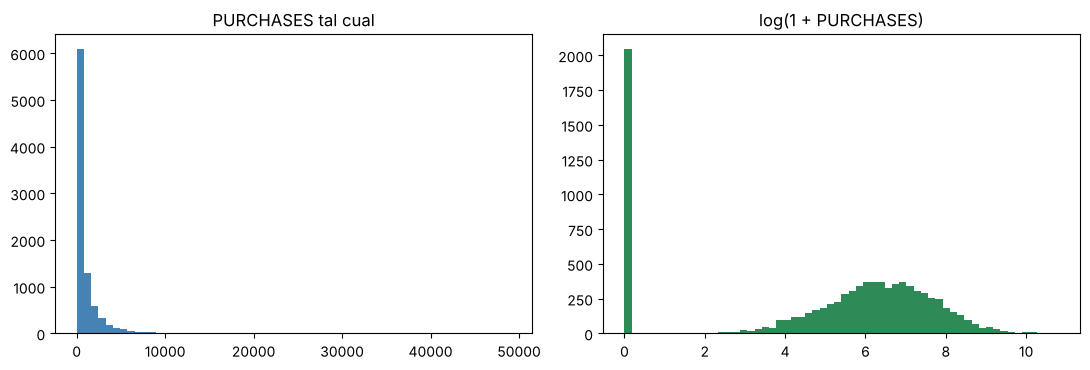

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(cc["PURCHASES"], bins=60, color="steelblue"); ax[0].set_title("PURCHASES tal cual")
ax[1].hist(con_log["PURCHASES"], bins=60, color="seagreen"); ax[1].set_title("log(1 + PURCHASES)")
plt.tight_layout(); plt.show()

**Interpretación.** A la izquierda casi todos los clientes se amontonan cerca de 0; a la derecha la forma es mucho más simétrica, con una barra en 0 que son los clientes que no compran.

**Paso 4: estandarizar.** K-Means mide **distancias**, igual que KNN. Si no escalamos, el límite de crédito (miles) aplastaría a la frecuencia de compras (entre 0 y 1). Estandarizar: $z=(x-\text{media})/\text{desviación}$. Ejemplo con dos clientes que compran casi lo mismo pero con límites y frecuencias muy distintos:

In [10]:
a = {"PURCHASES": 1000, "CREDIT_LIMIT": 3000, "PURCHASES_FREQUENCY": 0.9}
b = {"PURCHASES": 1100, "CREDIT_LIMIT": 9000, "PURCHASES_FREQUENCY": 0.1}
desv = cc[list(a)].std()
for v in a:
    print(f"{v:20s} diferencia cruda {abs(a[v] - b[v]):8.1f} | diferencia en desviaciones {abs(a[v] - b[v]) / desv[v]:.2f}")

PURCHASES            diferencia cruda    100.0 | diferencia en desviaciones 0.05
CREDIT_LIMIT         diferencia cruda   6000.0 | diferencia en desviaciones 1.65
PURCHASES_FREQUENCY  diferencia cruda      0.8 | diferencia en desviaciones 1.99


Sin escalar, la diferencia de límite (6 000) domina y la de frecuencia (0,8) no cuenta, aunque un cliente compra todos los meses y el otro casi nunca. En desviaciones, la frecuencia (≈ 2) pesa tanto como el límite (≈ 1,6).

# 4. Dividir en Train y Validation

En clustering no hay respuesta que predecir, pero sí queremos saber si los grupos **se sostienen con clientes nuevos**. Aprendemos los grupos (y el logaritmo y el escalado) con Train y luego asignamos a los clientes de Validation al grupo más cercano. Si en Validation los grupos se ven igual de bien que en Train, la segmentación es confiable.

In [11]:
train_cc, val_cc = train_test_split(cc, test_size=0.30, random_state=42)     # 70 % Train, 30 % Validation
print("Train:", len(train_cc), "clientes | Validation:", len(val_cc), "clientes")

def preparar(df):
    # Paso 3: logaritmo de los montos (no aprende nada, se aplica igual a cualquier tabla)
    d = df[VARS].copy()
    d[MONTOS] = np.log1p(d[MONTOS])
    return d

escalador = StandardScaler().fit(preparar(train_cc))     # Paso 4: medias y desviaciones aprendidas SOLO con Train
X_train = escalador.transform(preparar(train_cc))
X_val = escalador.transform(preparar(val_cc))
print("\nMedia y desviación de las 3 primeras columnas en Train:", X_train.mean(axis=0)[:3].round(2), X_train.std(axis=0)[:3].round(2))
print("Media y desviación en Validation (casi 0 y 1):        ", X_val.mean(axis=0)[:3].round(2), X_val.std(axis=0)[:3].round(2))
print("\nAsí llegan los datos a K-Means (primeras filas de Train):")
pd.DataFrame(X_train, columns=VARS).head(3).round(2)

Train: 6264 clientes | Validation: 2685 clientes

Media y desviación de las 3 primeras columnas en Train: [-0. -0. -0.] [1. 1. 1.]
Media y desviación en Validation (casi 0 y 1):         [-0.01  0.03  0.02] [1.01 1.   1.01]

Así llegan los datos a K-Means (primeras filas de Train):


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT
0,0.75,-1.67,-0.98,-1.09,1.74,-1.22,0.08,1.77,0.50
1,-1.53,0.31,-0.98,0.79,-0.94,-0.60,0.73,-1.07,-0.24
2,-1.54,0.09,-0.98,0.58,-0.94,0.64,-1.45,-0.86,2.90


In [12]:
# A mano, el primer cliente de Train en PURCHASES
x = preparar(train_cc)["PURCHASES"].iloc[0]
media, desviacion = escalador.mean_[1], escalador.scale_[1]
print(f"log(1 + compras) = {x:.3f} → z = ({x:.3f} − {media:.3f}) / {desviacion:.3f} = {(x - media) / desviacion:.3f}")
print("scikit-learn dice:", round(X_train[0, 1], 3))

log(1 + compras) = 0.000 → z = (0.000 − 4.878) / 2.918 = -1.671
scikit-learn dice: -1.671


# 5. K-Means a mano

**K-Means** divide los datos en `k` grupos. Cada grupo se representa con su **centroide** (el promedio de sus filas) y cada fila pertenece al grupo cuyo centroide está más cerca. **K** es el número de grupos y **Means** significa *medias*. Repite dos pasos hasta que nada cambia: (1) **asignar** cada punto al centro más cercano y (2) **mover** cada centro al promedio de sus puntos.

**Analogía.** Un banco quiere abrir `k` agencias para que cada cliente quede cerca de una: ubica agencias, asigna a cada cliente la más cercana, mueve cada agencia al centro de sus clientes y repite.

**Ejemplo con 12 clientes y una sola variable: el gasto mensual.** En el gráfico, el eje vertical es el gasto; el horizontal solo numera a los clientes para que los puntos no se amontonen (el modelo no lo usa). Empezamos con tres centros mal ubicados: 20, 35 y 40.

In [13]:
gasto = np.array([20, 35, 40, 55, 300, 320, 350, 380, 900, 950, 1000, 1100], dtype=float)
cliente = np.array([3, 9, 6, 12, 1, 7, 10, 4, 5, 11, 2, 8])      # solo para separar los puntos en el gráfico
centros = np.array([20.0, 35.0, 40.0])                           # centros iniciales (a propósito, mal ubicados)
for vuelta in range(1, 10):
    distancia = np.abs(gasto[:, None] - centros[None, :])        # distancia de cada cliente a cada centro
    grupo = distancia.argmin(axis=1)                             # paso 1: el centro más cercano
    nuevos = np.array([gasto[grupo == k].mean() for k in range(3)])   # paso 2: promedio de cada grupo
    print(f"Vuelta {vuelta}: centros {centros.round(1)} → nuevos centros {nuevos.round(1)}")
    if np.allclose(nuevos, centros):
        print("Los centros ya no cambian: terminó.")
        break
    centros = nuevos
print("Grupo de cada cliente:", dict(zip(gasto.astype(int), grupo)))

Vuelta 1: centros [20. 35. 40.] → nuevos centros [ 20.   35.  539.5]
Vuelta 2: centros [ 20.   35.  539.5] → nuevos centros [ 20.   43.3 662.5]
Vuelta 3: centros [ 20.   43.3 662.5] → nuevos centros [ 20.  183.3 866. ]
Vuelta 4: centros [ 20.  183.3 866. ] → nuevos centros [ 37.5 337.5 987.5]
Vuelta 5: centros [ 37.5 337.5 987.5] → nuevos centros [ 37.5 337.5 987.5]
Los centros ya no cambian: terminó.
Grupo de cada cliente: {np.int64(20): np.int64(0), np.int64(35): np.int64(0), np.int64(40): np.int64(0), np.int64(55): np.int64(0), np.int64(300): np.int64(1), np.int64(320): np.int64(1), np.int64(350): np.int64(1), np.int64(380): np.int64(1), np.int64(900): np.int64(2), np.int64(950): np.int64(2), np.int64(1000): np.int64(2), np.int64(1100): np.int64(2)}


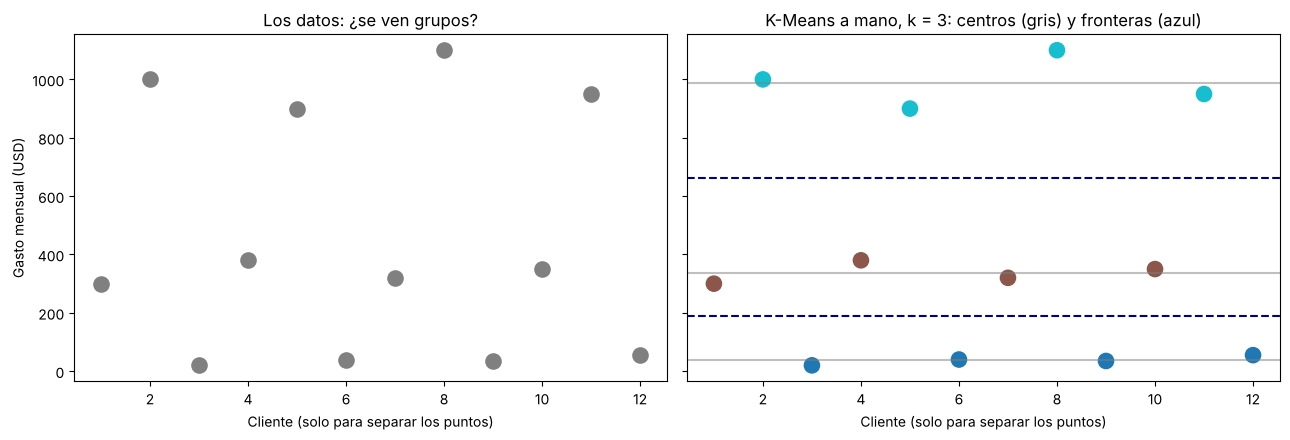

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
ax[0].scatter(cliente, gasto, s=120, color="gray"); ax[0].set(title="Los datos: ¿se ven grupos?", ylabel="Gasto mensual (USD)")
ax[1].scatter(cliente, gasto, s=120, c=grupo, cmap="tab10")
for c_ in centros: ax[1].axhline(c_, color="gray", alpha=0.5)
for f in (np.sort(centros)[:-1] + np.sort(centros)[1:]) / 2: ax[1].axhline(f, color="navy", ls="--")
ax[1].set(title="K-Means a mano, k = 3: centros (gris) y fronteras (azul)")
for a_ in ax: a_.set_xlabel("Cliente (solo para separar los puntos)")
plt.tight_layout(); plt.show()

**Lee la salida.** Aunque empezamos con los tres centros abajo, en pocas vueltas se mueven a **37,5**, **337,5** y **987,5**, los promedios de las tres franjas: $(20+35+40+55)/4=37{,}5$, etc. Las **fronteras** son los puntos medios entre centros: 187,5 y 662,5. Un cliente nuevo que gasta 500 está más cerca de 337,5: va al grupo del medio.

# 6. K-Means simple con scikit-learn

Igual que con los modelos supervisados, **tres pasos**: crear, entrenar (`fit`) y obtener resultados. La diferencia: `fit` recibe **solo X**, porque no hay `y`.

In [15]:
G = gasto.reshape(-1, 1)                        # scikit-learn pide una tabla: 12 filas, 1 columna
km_simple = KMeans(n_clusters=3, random_state=42, n_init=10)   # 1) crear: 3 grupos
km_simple.fit(G)                                # 2) entrenar: solo X, no hay y
print("Grupo de cada cliente (labels_):", km_simple.labels_)          # 3) resultados
print("Centros (cluster_centers_):", km_simple.cluster_centers_.ravel().round(1))
print("¿A qué grupo va un cliente nuevo de 500?", km_simple.predict([[500]]))

Grupo de cada cliente (labels_): [2 2 2 2 0 0 0 0 1 1 1 1]
Centros (cluster_centers_): [337.5 987.5  37.5]
¿A qué grupo va un cliente nuevo de 500? [0]


Los centros coinciden con el cálculo a mano (el orden de los números de grupo puede cambiar: son etiquetas, no un ranking). `predict` asigna una fila nueva al centro más cercano.

# 7. Las métricas: a mano y con scikit-learn

**Inercia** = suma de las distancias al cuadrado de cada punto a su centro. Más baja = grupos más compactos.

**Silhouette** de un punto: $a$ = distancia media a los de su grupo; $b$ = distancia media al grupo vecino más cercano; $s=(b-a)/\max(a,b)$. Cerca de 1: bien ubicado; cerca de 0: en la frontera; negativo: probablemente en el grupo equivocado. El Silhouette del modelo es el **promedio** de todos los puntos.

A mano, con el cliente que gasta 55: está con 20, 35 y 40, así que $a=(35+20+15)/3=23{,}3$; su grupo vecino es el de 300 a 380: $b=(245+265+295+325)/4=282{,}5$; $s=(282{,}5-23{,}3)/282{,}5=0{,}92$.

In [16]:
etiquetas = km_simple.labels_
centro_de_cada = km_simple.cluster_centers_.ravel()[etiquetas]
inercia_mano = ((gasto - centro_de_cada) ** 2).sum()                 # suma de distancias al cuadrado
print(f"Inercia a mano: {inercia_mano:.1f} | scikit-learn (inertia_): {km_simple.inertia_:.1f}")

i55 = 3                                                              # posición del cliente que gasta 55
mismo = gasto[(etiquetas == etiquetas[i55]) & (np.arange(12) != i55)]
vecino = gasto[etiquetas == etiquetas[4]]                            # el grupo de 300 a 380
a_, b_ = np.abs(mismo - 55).mean(), np.abs(vecino - 55).mean()
print(f"Silhouette del cliente 55 a mano: a = {a_:.1f}, b = {b_:.1f}, s = {(b_ - a_) / max(a_, b_):.2f}")
print("Silhouette de cada cliente (scikit-learn):", silhouette_samples(G, etiquetas).round(2))
print("Silhouette promedio del modelo:", round(silhouette_score(G, etiquetas), 3))

Inercia a mano: 26175.0 | scikit-learn (inertia_): 26175.0
Silhouette del cliente 55 a mano: a = 23.3, b = 282.5, s = 0.92
Silhouette de cada cliente (scikit-learn): [0.93 0.96 0.96 0.92 0.81 0.87 0.88 0.83 0.79 0.86 0.87 0.8 ]
Silhouette promedio del modelo: 0.874


**Línea base: los cuartiles.** Una segmentación simple, sin Machine Learning: 4 grupos de 3 clientes según el gasto. Si K-Means no le gana, no vale la pena.

In [17]:
cuartiles = np.repeat([0, 1, 2, 3], 3)          # los 12 clientes ya están ordenados por gasto
print("Silhouette de cada cliente con cuartiles:", silhouette_samples(G, cuartiles).round(2))
print("Silhouette promedio — cuartiles:", round(silhouette_score(G, cuartiles), 3), "| K-Means:", round(silhouette_score(G, etiquetas), 3))

Silhouette de cada cliente con cuartiles: [ 0.91  0.95  0.93 -0.91  0.46  0.36 -0.57 -0.44 -0.78  0.75  0.84  0.78]
Silhouette promedio — cuartiles: 0.273 | K-Means: 0.874


Con cuartiles, el cliente de 55 queda con los de 300 y 320 y su Silhouette es **negativo** (−0,91): está en el grupo equivocado. K-Means sigue los huecos de los datos.

### Ahora con los clientes reales: Train frente a Validation

Entrenamos K-Means con `k = 4` en Train, asignamos los clientes de Validation con `predict` y comparamos: si el Silhouette y los tamaños se parecen, los grupos se sostienen con clientes nuevos.

In [18]:
km4 = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X_train)       # aprender los grupos con Train
grupos_train = km4.labels_
grupos_val = km4.predict(X_val)                                           # asignar clientes nuevos al centro más cercano
print("Inercia en Train:", round(km4.inertia_))
print("Silhouette en Train:     ", round(silhouette_score(X_train, grupos_train, sample_size=4000, random_state=0), 3))
print("Silhouette en Validation:", round(silhouette_score(X_val, grupos_val), 3))
pd.DataFrame({"% clientes Train": pd.Series(grupos_train).value_counts(normalize=True).sort_index() * 100,
              "% clientes Validation": pd.Series(grupos_val).value_counts(normalize=True).sort_index() * 100}).round(1)

Inercia en Train: 28776


Silhouette en Train:      0.271
Silhouette en Validation: 0.268


,% clientes Train,% clientes Validation
0,14.0,14.7
1,27.5,26.4
2,31.5,31.1
3,26.9,27.7


**Interpretación.** El Silhouette y el porcentaje de clientes de cada grupo son casi iguales en Train y en Validation: los grupos **generalizan**. Un Silhouette de ≈ 0,27 indica grupos reales pero con fronteras difusas, algo normal en datos de comportamiento.

# 8. Los hiperparámetros de K-Means, uno por uno

| Hiperparámetro | Qué controla | Valor por defecto | Valor de hoy |
|---|---|---|---|
| `n_clusters` (k) | Cuántos grupos | 8 | se elige en la sección 9 |
| `init` | Cómo se eligen los centros iniciales: `"k-means++"` (separados entre sí) o `"random"` (al azar) | `"k-means++"` | `"k-means++"` |
| `n_init` | Cuántas veces se repite desde puntos de partida distintos; se queda con la menor inercia | `"auto"` | 20 |
| `max_iter` | Máximo de vueltas de asignar y mover centros | 300 | 300 |
| `random_state` | Semilla: el mismo resultado cada vez | `None` | 42 |
| *La preparación* | Qué variables, logaritmo, escalado | — | 9 variables, log, z |

Veamos por qué importa `n_init`: con un solo punto de partida, distintas semillas pueden llegar a soluciones distintas.

In [19]:
filas = []
for semilla in range(6):
    m1 = KMeans(n_clusters=4, n_init=1, init="random", random_state=semilla).fit(X_train)    # un solo intento, inicio al azar
    m20 = KMeans(n_clusters=4, n_init=20, random_state=semilla).fit(X_train)                # veinte intentos
    filas.append({"semilla": semilla, "inercia n_init=1": round(m1.inertia_), "inercia n_init=20": round(m20.inertia_),
                  "¿mismos grupos que la referencia? (ARI, n_init=1)": round(adjusted_rand_score(km4.labels_, m1.labels_), 2)})
pd.DataFrame(filas)

,semilla,inercia n_init=1,inercia n_init=20,"¿mismos grupos que la referencia? (ARI, n_init=1)"
0,0,29531,28776,0.62
1,1,28776,28776,0.99
2,2,29343,28776,0.51
3,3,28776,28776,0.97
4,4,28776,28776,0.96
5,5,28776,28776,1.00


**Interpretación.** Con un solo intento, algunas semillas terminan con más inercia (peor solución) y grupos distintos (el ARI vale 1 cuando dos particiones coinciden). Con `n_init=20` todas llegan a la misma solución. **Siempre usa varios intentos** y fija `random_state`.

# 9. Probar combinaciones con un `for`

Recorremos `k` de 2 a 8 con dos preparaciones (con y sin logaritmo) y medimos, en Train y en Validation, el Silhouette y el tamaño del grupo más chico. Incluimos la **línea base**: 4 grupos por cuartiles de compras.

In [20]:
X_train_sinlog = StandardScaler().fit(train_cc[VARS]).transform(train_cc[VARS])      # misma escala, sin logaritmo
esc_sinlog = StandardScaler().fit(train_cc[VARS]); X_val_sinlog = esc_sinlog.transform(val_cc[VARS])
filas = []
for nombre, Xtr, Xva in [("con log", X_train, X_val), ("sin log", X_train_sinlog, X_val_sinlog)]:
    for k in range(2, 9):
        m = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Xtr)
        g_val = m.predict(Xva)
        filas.append({"preparación": nombre, "k": k, "inercia": round(m.inertia_),
                      "silhouette_train": silhouette_score(Xtr, m.labels_, sample_size=4000, random_state=0),
                      "silhouette_val": silhouette_score(Xva, g_val),
                      "grupo_mas_chico_%": 100 * np.bincount(m.labels_).min() / len(m.labels_)})
rejilla = pd.DataFrame(filas).round(3)
base_q = pd.qcut(train_cc["PURCHASES"].rank(method="first"), 4, labels=False)        # línea base en Train
print("Línea base (cuartiles de compras) → Silhouette en Train:", round(silhouette_score(X_train, base_q, sample_size=4000, random_state=0), 3))
rejilla

Línea base (cuartiles de compras) → Silhouette en Train: 0.139


,preparación,k,inercia,silhouette_train,silhouette_val,grupo_mas_chico_%
0,con log,2,40567,0.278,0.273,33.525
1,con log,3,33213,0.263,0.263,30.699
2,con log,4,28776,0.271,0.268,14.033
3,con log,5,25614,0.270,0.271,12.723
4,con log,6,23223,0.282,0.282,3.464
5,con log,7,21423,0.274,0.275,3.257
6,con log,8,19972,0.239,0.237,3.033
7,sin log,2,45475,0.475,0.475,13.458
8,sin log,3,38653,0.382,0.350,4.949
9,sin log,4,32287,0.268,0.272,1.325


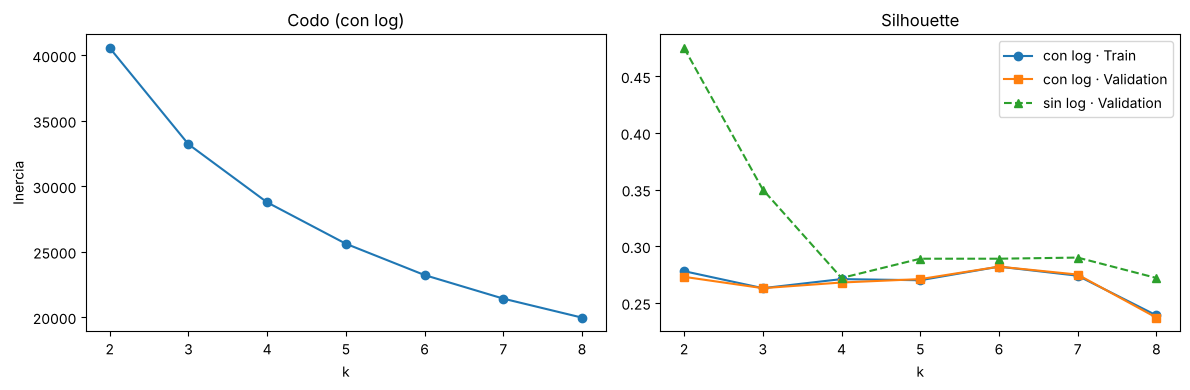

In [21]:
con, sin = rejilla[rejilla["preparación"] == "con log"], rejilla[rejilla["preparación"] == "sin log"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(con["k"], con["inercia"], marker="o"); ax[0].set(title="Codo (con log)", xlabel="k", ylabel="Inercia")
ax[1].plot(con["k"], con["silhouette_train"], marker="o", label="con log · Train")
ax[1].plot(con["k"], con["silhouette_val"], marker="s", label="con log · Validation")
ax[1].plot(sin["k"], sin["silhouette_val"], marker="^", ls="--", label="sin log · Validation")
ax[1].set(title="Silhouette", xlabel="k"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lee los resultados con cuidado.**

- **Línea base:** Silhouette ≈ 0,14. Cualquier K-Means con logaritmo la duplica.
- **Sin logaritmo, k = 2 tiene el Silhouette más alto (≈ 0,47).** Parece la mejor opción, pero su grupo más chico es de solo 13 %: separa a los clientes «grandes» (saldo, límite y pagos altos) del resto. Es obvio e inútil. Y con k ≥ 4 sin logaritmo aparecen grupos de menos del 2 %: unos pocos clientes extremos. **Un Silhouette alto no basta: mira los tamaños.**
- **Con logaritmo**, el Silhouette queda entre 0,24 y 0,28 para todos los `k`, casi igual en Train y en Validation: los grupos se sostienen con clientes nuevos.
- **k = 6 con logaritmo tiene el Silhouette más alto (0,28)**, pero su grupo más chico es de 3,5 %: descartado por la misma razón.
- **k = 2 con logaritmo (0,28)** solo separa «compra» de «no compra»: demasiado grueso para decidir campañas.
- **El codo:** la inercia baja mucho hasta k = 4 y luego cada grupo extra aporta menos.
- **Elegimos k = 4 con logaritmo:** Silhouette casi igual al mejor (0,27 frente a 0,28), el doble de la línea base, igual en Validation, todos los grupos con más del 10 % de clientes y, como veremos, perfiles que se pueden explicar.

# 10. Modelo final: describir los grupos

In [22]:
kmeans_final = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X_train)
train_cc = train_cc.assign(segmento=kmeans_final.labels_)
print("Clientes de Train por segmento:"); print(train_cc["segmento"].value_counts().sort_index())
train_cc.groupby("segmento")[VARS].median().round(2).T             # medianas en unidades originales

Clientes de Train por segmento:
segmento
0     879
1    1725
2    1973
3    1687
Name: count, dtype: int64


segmento,0,1,2,3
BALANCE,88.24,1457.38,1877.42,120.63
PURCHASES,928.53,0.00,1199.77,283.30
ONEOFF_PURCHASES,95.00,0.00,695.90,0.00
INSTALLMENTS_PURCHASES,469.89,0.00,355.80,126.48
CASH_ADVANCE,0.00,1242.65,148.68,0.00
PURCHASES_FREQUENCY,0.92,0.00,0.83,0.50
CREDIT_LIMIT,4000.00,3000.00,6000.00,1800.00
PAYMENTS,1077.06,797.03,1660.24,338.41
PRC_FULL_PAYMENT,0.83,0.00,0.00,0.00


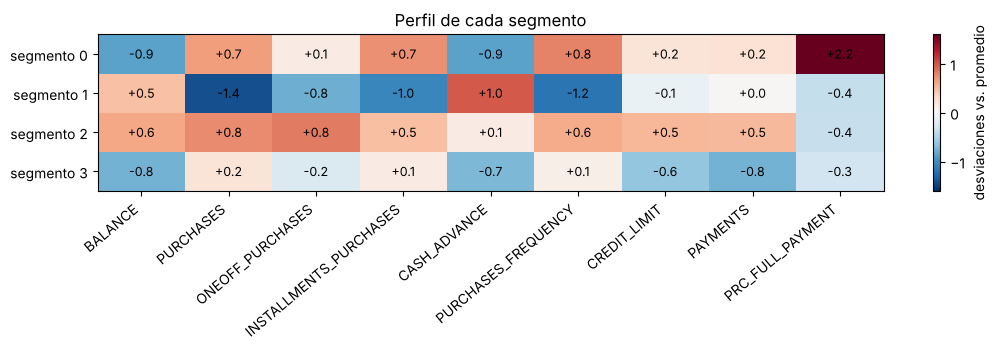

In [23]:
perfil = pd.DataFrame(X_train, columns=VARS).groupby(kmeans_final.labels_).mean()   # promedio de cada segmento en z
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(perfil.values, cmap="RdBu_r", vmin=-1.6, vmax=1.6, aspect="auto")
ax.set_xticks(range(len(VARS))); ax.set_xticklabels(VARS, rotation=40, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels([f"segmento {k}" for k in range(4)])
for i in range(4):
    for j in range(len(VARS)):
        ax.text(j, i, f"{perfil.values[i, j]:+.1f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="desviaciones vs. promedio"); plt.title("Perfil de cada segmento"); plt.tight_layout(); plt.show()

**Cómo leer el mapa de calor.** Rojo: el segmento está por encima del promedio en esa variable; azul: por debajo. Leemos fila por fila y ponemos un nombre que describa el comportamiento. Los números de segmento son etiquetas arbitrarias. Con estos datos aparecen cuatro perfiles:

| Perfil | Lo que lo distingue | Idea de uso |
|---|---|---|
| **Compradores que financian** | Saldo alto, compran mucho y seguido, límite alto, casi nunca pagan el total | Ofertas de cuotas; vigilar el endeudamiento |
| **Totaleros** | Saldo muy bajo, compran casi todos los meses, pagan el total la mayoría de los meses | Programas de recompensas; bajo riesgo |
| **Usuarios de avances en efectivo** | Casi no compran y usan avances en efectivo; saldo alto | Posible necesidad de liquidez: revisar riesgo y ofrecer otros productos |
| **Poco activos** | Saldo, compras, pagos y límite bajos | Campañas de activación |

**Cuidado.** Los grupos describen comportamiento de 6 meses según **nuestras** variables. No prueban causas ni son categorías oficiales; con otras variables saldrían otros grupos.

# 11. Clustering jerárquico

## 11.1 A mano

El clustering **jerárquico aglomerativo** empieza con cada fila como su propio grupo y en cada paso **une los dos grupos más cercanos**, hasta que queda uno solo. El **dendrograma** dibuja esas uniones; el número de grupos se elige **cortándolo** con una línea horizontal. No hay que decidir `k` al inicio y siempre da el mismo resultado, pero es lento con muchos datos porque compara todos los pares.

Cinco clientes en una recta: A = 1, B = 2, C = 6, D = 7, E = 15. Matriz de distancias:

| | A = 1 | B = 2 | C = 6 | D = 7 | E = 15 |
|---|---:|---:|---:|---:|---:|
| A | — | **1** | 5 | 6 | 14 |
| B | | — | 4 | 5 | 13 |
| C | | | — | **1** | 9 |
| D | | | | — | 8 |

| Paso | Distancia menor | Se unen | Centro del grupo nuevo |
|---|---|---|---|
| 1 | 1 (A-B) | A y B | 1,5 |
| 2 | 1 (C-D) | C y D | 6,5 |
| 3 | 6,5 − 1,5 = 5 | {A, B} y {C, D} | 4 |
| 4 | 15 − 4 = 11 | {A, B, C, D} y E | — |

Cortar a altura 3 deja 3 grupos ({A, B}, {C, D}, {E}); a altura 8 deja 2 ({A, B, C, D}, {E}).

Uniones [grupo 1, grupo 2, distancia, tamaño]:
[[ 0.  1.  1.  2.]
 [ 2.  3.  1.  2.]
 [ 5.  6.  5.  4.]
 [ 4.  7. 11.  5.]]


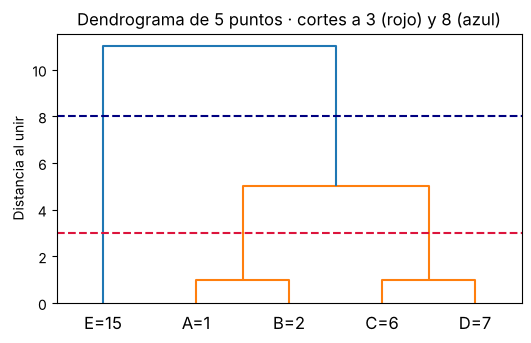

In [24]:
recta5 = np.array([[1], [2], [6], [7], [15]], dtype=float)
Z5 = linkage(recta5, method="centroid")        # cada fila de Z5: qué grupos se unen y a qué distancia
print("Uniones [grupo 1, grupo 2, distancia, tamaño]:"); print(Z5.round(2))
plt.figure(figsize=(6, 3.5))
dendrogram(Z5, labels=["A=1", "B=2", "C=6", "D=7", "E=15"])
plt.axhline(3, color="crimson", ls="--"); plt.axhline(8, color="navy", ls="--")
plt.title("Dendrograma de 5 puntos · cortes a 3 (rojo) y 8 (azul)"); plt.ylabel("Distancia al unir"); plt.show()

## 11.2 El modelo simple con scikit-learn

In [25]:
jer_simple = AgglomerativeClustering(n_clusters=2, linkage="ward")   # 1) crear: 2 grupos, regla de unión Ward
grupos5 = jer_simple.fit_predict(recta5)                              # 2) y 3) unir y devolver el grupo de cada punto
print("Grupo de A, B, C, D y E:", grupos5)
print("Silhouette:", round(silhouette_score(recta5, grupos5), 3))

Grupo de A, B, C, D y E: [0 0 0 0 1]
Silhouette: 0.518


Igual que cortar a altura 8: {A, B, C, D} y {E}. El jerárquico **no tiene `predict`**: para un cliente nuevo hay que volver a construir el árbol. Por eso se usa con pocos datos o con una muestra.

## 11.3 Los hiperparámetros del jerárquico

| Hiperparámetro | Qué controla | Valor por defecto |
|---|---|---|
| `n_clusters` | Cuántos grupos quedan al cortar el árbol | 2 |
| `linkage` | Cómo se mide la distancia entre dos grupos: `"ward"` (la unión que menos aumenta la variación interna), `"complete"` (puntos más lejanos), `"average"` (promedio), `"single"` (puntos más cercanos) | `"ward"` |
| `metric` | Cómo se mide la distancia entre dos puntos (Ward solo admite euclidiana) | `"euclidean"` |
| `distance_threshold` | En lugar de `n_clusters`: cortar el árbol a una altura dada | `None` |

## 11.4 Con los clientes reales: dendrograma y `for` con las reglas de unión

Usamos una muestra de 2 000 clientes de Train, ya preparados (logaritmo y escalado).

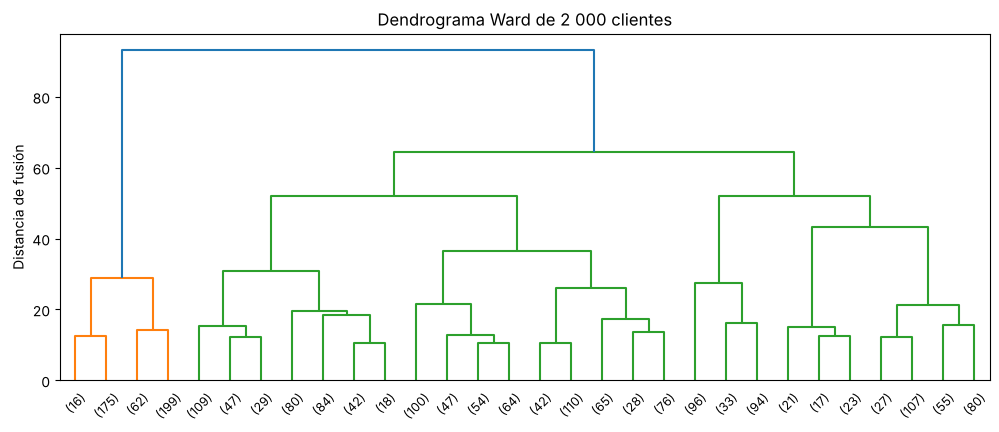

In [26]:
rng = np.random.RandomState(42)
idx = rng.choice(len(X_train), 2000, replace=False)
X_muestra = X_train[idx]
plt.figure(figsize=(12, 4.5))
dendrogram(linkage(X_muestra, method="ward"), truncate_mode="lastp", p=30, leaf_font_size=9)   # solo las últimas 30 uniones
plt.title("Dendrograma Ward de 2 000 clientes"); plt.ylabel("Distancia de fusión"); plt.show()

**Lee el dendrograma.** Los números entre paréntesis en la base son cuántos clientes agrupa cada rama. Las uniones de arriba ocurren a gran altura: son grupos muy distintos. Un corte justo debajo de las tres últimas uniones deja 4 grupos.

In [27]:
filas = []
for regla in ["ward", "complete", "average", "single"]:
    for k in [3, 4, 5]:
        g = AgglomerativeClustering(n_clusters=k, linkage=regla).fit_predict(X_muestra)
        filas.append({"linkage": regla, "k": k, "silhouette": silhouette_score(X_muestra, g),
                      "tamaños": sorted(np.bincount(g).tolist(), reverse=True),
                      "grupo_mas_chico_%": 100 * np.bincount(g).min() / len(g),
                      "ARI vs K-Means": adjusted_rand_score(kmeans_final.labels_[idx], g) if k == 4 else np.nan})
pd.DataFrame(filas).round(3)

,linkage,k,silhouette,tamaños,grupo_mas_chico_%,ARI vs K-Means
0,ward,3,0.234,"[995, 553, 452]",22.60,NaN
1,ward,4,0.247,"[995, 452, 330, 223]",11.15,0.487
2,ward,5,0.252,"[586, 452, 409, 330, 223]",11.15,NaN
3,complete,3,0.129,"[1272, 665, 63]",3.15,NaN
4,complete,4,0.219,"[824, 665, 448, 63]",3.15,0.394
5,complete,5,0.218,"[824, 561, 448, 104, 63]",3.15,NaN
6,average,3,0.233,"[1936, 61, 3]",0.15,NaN
7,average,4,0.174,"[1929, 61, 7, 3]",0.15,0.003
8,average,5,0.083,"[1926, 61, 7, 3, 3]",0.15,NaN
9,single,3,0.243,"[1992, 7, 1]",0.05,NaN


**Interpretación.** *Average* y *single* tienen Silhouette parecido o mayor que Ward, pero mira los tamaños: dejan casi todos los clientes en un grupo y aíslan unos pocos casos extremos. Para segmentar son inútiles (sirven, en cambio, para encontrar casos raros). **Ward** da grupos equilibrados y, con k = 4, coincide moderadamente con K-Means (ARI ≈ 0,5): encuentran una estructura parecida, no idéntica.

# 12. Comparación final: todos los métodos en todos los datasets del día

Hoy usamos tres «datasets»: los **12 clientes** del ejemplo, los clientes reales con **una sola variable** (log de compras) y los clientes reales con **las 9 variables**. Aplicamos a cada uno la línea base y todos los métodos con el mismo número de grupos, y medimos:

- **Silhouette** (más alto = grupos más separados) y
- **tamaño del grupo más chico** (%): si es menor a 5 %, el método solo está aislando casos raros.

Regla para escoger: **el mayor Silhouette entre los métodos cuyo grupo más chico tiene al menos 5 %**. Para que todos se midan igual, en los datos reales usamos la misma muestra de 2 000 clientes.

In [28]:
una_var = escalador.transform(preparar(train_cc))[:, [VARS.index("PURCHASES")]]   # log de compras, escalado
datasets = {"12 clientes (gasto)": (G, 3, cuartiles),
            "Clientes · solo compras": (una_var[idx], 3, pd.qcut(pd.Series(una_var[idx, 0]).rank(method="first"), 3, labels=False).values),
            "Clientes · 9 variables": (X_muestra, 4, pd.qcut(train_cc["PURCHASES"].iloc[idx].rank(method="first"), 4, labels=False).values)}
metodos = {"K-Means": lambda k: KMeans(n_clusters=k, n_init=20, random_state=42),
           "Jerárquico Ward": lambda k: AgglomerativeClustering(n_clusters=k, linkage="ward"),
           "Jerárquico complete": lambda k: AgglomerativeClustering(n_clusters=k, linkage="complete"),
           "Jerárquico average": lambda k: AgglomerativeClustering(n_clusters=k, linkage="average"),
           "Jerárquico single": lambda k: AgglomerativeClustering(n_clusters=k, linkage="single")}
filas = []
for nombre_ds, (Xd, k, base) in datasets.items():
    filas.append({"dataset": nombre_ds, "método": "Línea base (cuantiles)", "k": len(np.unique(base)),
                  "silhouette": silhouette_score(Xd, base), "grupo_mas_chico_%": 100 * np.bincount(base).min() / len(base)})
    for nombre_m, crear in metodos.items():
        g = crear(k).fit_predict(Xd)
        filas.append({"dataset": nombre_ds, "método": nombre_m, "k": k,
                      "silhouette": silhouette_score(Xd, g), "grupo_mas_chico_%": 100 * np.bincount(g).min() / len(g)})
comparacion = pd.DataFrame(filas).round(3)
comparacion

,dataset,método,k,silhouette,grupo_mas_chico_%
0,12 clientes (gasto),Línea base (cuantiles),4,0.273,25.000
1,12 clientes (gasto),K-Means,3,0.874,33.333
2,12 clientes (gasto),Jerárquico Ward,3,0.874,33.333
3,12 clientes (gasto),Jerárquico complete,3,0.874,33.333
4,12 clientes (gasto),Jerárquico average,3,0.874,33.333
5,12 clientes (gasto),Jerárquico single,3,0.874,33.333
6,Clientes · solo compras,Línea base (cuantiles),3,0.535,33.300
7,Clientes · solo compras,K-Means,3,0.653,23.900
8,Clientes · solo compras,Jerárquico Ward,3,0.653,23.650
9,Clientes · solo compras,Jerárquico complete,3,0.550,8.900


In [29]:
print("Silhouette (filas: método, columnas: dataset):")
print(comparacion.pivot(index="método", columns="dataset", values="silhouette").round(3))
print()
for nombre_ds in datasets:
    validos = comparacion[(comparacion["dataset"] == nombre_ds) & (comparacion["grupo_mas_chico_%"] >= 5)]
    g = validos.sort_values("silhouette", ascending=False).iloc[0]
    print(f"{nombre_ds:25s} → gana {g['método']:22s} (Silhouette {g['silhouette']:.3f}, grupo más chico {g['grupo_mas_chico_%']:.1f} %)")

Silhouette (filas: método, columnas: dataset):
dataset                 12 clientes (gasto)  Clientes · 9 variables  Clientes · solo compras
método                                                                                      
Jerárquico Ward                       0.874                   0.247                    0.653
Jerárquico average                    0.874                   0.174                    0.591
Jerárquico complete                   0.874                   0.219                    0.550
Jerárquico single                     0.874                   0.233                    0.666
K-Means                               0.874                   0.266                    0.653
Línea base (cuantiles)                0.273                   0.138                    0.535

12 clientes (gasto)       → gana K-Means                (Silhouette 0.874, grupo más chico 33.3 %)
Clientes · solo compras   → gana K-Means                (Silhouette 0.653, grupo más chico 23.9 %)
Clientes ·

### ¿Por qué gana un método distinto en cada caso?

- **12 clientes:** los grupos son tres franjas muy separadas; todos los métodos encuentran exactamente las mismas franjas (Silhouette cercano a 0,9). La línea base de cuartiles, que corta sin mirar los huecos, queda muy abajo.
- **Clientes, solo compras:** con una variable, los grupos son tramos de una recta; K-Means y Ward los dibujan casi igual (0,653). *Single* tiene un Silhouette apenas mayor (0,666), pero su grupo más chico es el 0,1 % de los clientes: aísla unos pocos extremos y queda descartado por tamaño, igual que *average*.
- **Clientes, 9 variables:** los grupos son difusos (Silhouette ≈ 0,2–0,3). Entre los métodos con grupos de tamaño útil gana K-Means (0,266), seguido de Ward (0,247). Con miles de clientes, **K-Means** es además el práctico: es rápido y puede asignar clientes nuevos con `predict`.

**Lecciones:**

1. **Siempre compara con una línea base sencilla.** Si el modelo no le gana, no aporta.
2. **El Silhouette solo no basta:** mira los tamaños. Un método que aísla 3 clientes raros puede tener buen Silhouette y no servir para segmentar.
3. **Comprueba en Validation** que los grupos se sostienen con clientes nuevos.
4. **Describe los grupos** en unidades originales y con nombres de comportamiento: es lo que vuelve útil un clustering.

# Actividad autónoma

1. Quita el logaritmo y repite el modelo final con k = 4. ¿Qué perfiles cambian? ¿Cuál solución explicarías mejor a un gerente?
2. Agrega `CASH_ADVANCE_FREQUENCY` y `MINIMUM_PAYMENTS` a `VARS`. ¿Aparece un segmento nuevo con k = 5? ¿Se sostiene en Validation?
3. Cambia la línea base: cuartiles de `BALANCE` en lugar de `PURCHASES`. ¿K-Means sigue ganando?
4. En la sección 11.4, prueba `linkage="ward"` con k = 6. ¿Cómo cambian los tamaños?
5. Escribe en 150 palabras qué acción comercial o de riesgo propondrías para el segmento de avances en efectivo, y qué dato adicional pedirías antes de aplicarla.